# Proyecto 2 - Diseño Interactivo de Filtros Digitales en el Plano Z
**Materia**: Procesamiento Digital de Señales

**Grupo**: 03

**Equipo**: 02

### Integrantes:
* Espinoza Matamoros Percival Ulises
* Lugo Manzano Rodrigo
* García Cortés Adolfo de Jésus


## Importacion y Configuracion Bibliotecas

In [1]:
!pip install ipympl -q
from google.colab import output
output.enable_custom_widget_manager()

Nota: Despúes de ejecutar la primera celda para evitar mensajes de Error de Google Collab, se debe de reiniciar la sesión `CTRL + M + .` o en la barra de Herramientas `Entorno de Ejecucion -> Reinicicar la Sesión`.

Una vez reiniciada la sesión volver a ejecutar la primer celda y luego las demás

In [2]:
import matplotlib.pyplot as plt
%matplotlib widget

## Fudamento Matemático (*Motor LTI* )

In [3]:
import numpy as np
import scipy.signal as sig
import re

In [4]:
class MotorLTI:
    def __init__(self):
        self.polos = []
        self.ceros = []
        self.K = 1.0

    # Parseo Cadenas de Caracteres a Número Complejo
    def leer_complejo(self, texto):
        cadena = texto.replace(' ', '').lower()
        cadena = re.sub(r'(^|[-+])j', r'\g<1>1j', cadena)
        return complex(cadena)

    # Añadir Polos / Ceros (a partir de texto)
    def agregar_raiz(self, tipo_raiz, valor_str):
        self.agregar_valor(tipo_raiz, self.leer_complejo(valor_str))

    # Añadir Polos / Ceros (a partir de un número complejo; lo usan el texto y el clic en el plano)
    def agregar_valor(self, tipo_raiz, valor):
        destino = self.polos if tipo_raiz == 'p' else self.ceros

        destino.append(valor)
        # Si tiene parte imaginaria, se añade su conjugado
        if abs(valor.imag) > 1e-5:
            destino.append(np.conj(valor))

    # Eliminar Polos / Ceros
    def eliminar_raiz(self, tipo_raiz, indice):
        destino = self.polos if tipo_raiz == 'p' else self.ceros
        if indice >= len(destino): return

        valor = destino.pop(indice)
        if abs(valor.imag) > 1e-5:
            # Buscar y eliminar el conjugado
            indice_conjugado = next((i for i, v in enumerate(destino) if np.isclose(v, np.conj(valor))), None)
            if indice_conjugado is not None:
                destino.pop(indice_conjugado)

    # Función para actualizar la posición de una raíz cuando se arrastra en la UI
    # Nota: Se conserva la simetría conjugada automáticamente y NO cambia la cantidad de raíces:
    #   - una raíz real solo se mueve sobre el eje real
    #   - un par complejo se mueve junto con su conjugado
    def actualizar_posicion_raiz(self, tipo_raiz, indice, nuevo_valor):
        destino = self.polos if tipo_raiz == 'p' else self.ceros
        if indice < 0 or indice >= len(destino):
            return

        valor_anterior = destino[indice]

        # Si el valor anterior era real, se mueve únicamente sobre el eje real
        if abs(valor_anterior.imag) < 1e-5:
            destino[indice] = complex(nuevo_valor.real, 0.0)
        # En caso de que el valor anterior sea complejo, se actualiza el valor y su conjugado correspondiente
        else:
            indice_conjugado = next(
                (
                    i for i, valor in enumerate(destino)
                    if i != indice and np.isclose(valor, np.conj(valor_anterior))
                ),
                None,
            )
            destino[indice] = nuevo_valor
            if indice_conjugado is not None:
                destino[indice_conjugado] = np.conj(nuevo_valor)

    # Obtener Coeficientes del Numerador y Denominador de H(z)
    def obtener_coeficientes_ft(self):
        num = np.poly(self.ceros) if self.ceros else [1.0]
        den = np.poly(self.polos) if self.polos else [1.0]
        return np.real(num) * self.K, np.real(den)

    # Coeficientes en potencias de z^-1 de un sistema CAUSAL con H(z) = Y(z)/X(z)
    # - Si hay mas polos que ceros se anteponen P-M ceros al numerador.
    # - Si hay mas ceros que polos Se añaden M-P polos en el origen
    def obtener_coeficientes_causales(self):
        num, den = self.obtener_coeficientes_ft()
        M, P = len(num) - 1, len(den) - 1
        if P >= M:
            return np.concatenate([np.zeros(P - M), num]), den
        return num, np.concatenate([den, np.zeros(M - P)])

    def es_causal(self):
        num, den = self.obtener_coeficientes_ft()
        return len(num) <= len(den)

    # Frecuencias (rad) de los polos que están sobre el círculo unitario
    def polos_sobre_circulo(self, tolerancia=1e-6):
        return sorted({round(float(abs(np.angle(p))), 4) for p in self.polos if abs(abs(p) - 1) < tolerancia})

    # Calculo de la Respuesta en Frecuencia: H(e^jw) = H(z) evaluada en z = e^jw
    def obtener_respuesta_frecuencial(self, arreglo_w):
        num, den = self.obtener_coeficientes_ft()
        z = np.exp(1j * np.asarray(arreglo_w, dtype=float))
        num_val, den_val = np.polyval(num, z), np.polyval(den, z)
        indefinida = np.abs(den_val) < 1e-9
        h = num_val / np.where(indefinida, 1.0, den_val)
        h = np.where(indefinida, np.nan, h)
        return np.abs(h), np.angle(h)

    # Calculo de la Respuuesta al impulso h[n]
    def obtener_respuesta_impulso(self, num_muestras=50):
        b, a = self.obtener_coeficientes_causales()
        impulso = np.zeros(num_muestras)
        impulso[0] = 1.0
        return sig.lfilter(b, a, impulso)

    # Método para limpiar todos los polos y ceros
    def limpiar_todo(self):
        self.polos = []
        self.ceros = []

## Interfáz Gráfica (*UI* - Interfaz Plano Z)

***Controles:***
* `Arrastrar - Click Izquierdo`:  **Mover Polo/Cero**
* `Click Derecho`:  **Eliminar Polo/Cero**

In [11]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML

In [6]:
from io import BytesIO
from matplotlib.figure import Figure
from IPython.display import Image

# Crear un motor con polos y ceros ya cargados
def crear_motor(polos, ceros, K=1.0):
    motor = MotorLTI()
    motor.K = K
    for p in polos: motor.agregar_raiz('p', p)
    for z in ceros: motor.agregar_raiz('z', z)
    return motor

# Formato de un número complejo: 0.50+0.50j
def formato_numero(c):
    return f"{c.real:.2f}{'+' if c.imag >= 0 else '-'}{abs(c.imag):.2f}j"

# Formato de un factor (z - r): (z - 0.80), (z + 1.00) o (z - (0.50 + 0.50j))
def formato_raiz(r):
    if abs(r.imag) < 1e-9:
        a = r.real + 0.0
        return f"(z - {a:.2f})" if a >= 0 else f"(z + {abs(a):.2f})"
    return f"(z - ({r.real:.2f} {'+' if r.imag >= 0 else '-'} {abs(r.imag):.2f}j))"

# Formato de un polinomio en z a partir de sus coeficientes (orden descendente): 1.00z^2 + 0.81
def formato_polinomio(coefs):
    n = len(coefs) - 1
    terminos = []
    for i, c in enumerate(coefs):
        c = float(np.real(c)); p = n - i
        if abs(c) < 1e-9 and n > 0: continue
        mag = f"{abs(c):.2f}"
        t = mag if p == 0 else (f"{mag}z" if p == 1 else f"{mag}z^{p}")
        terminos.append((c < 0, t))
    if not terminos: return "0"
    s = ("-" if terminos[0][0] else "") + terminos[0][1]
    for neg, t in terminos[1:]:
        s += (" - " if neg else " + ") + t
    return s

# Panel con estabilidad, ceros, polos, K, H(z) factorizada y coeficientes
def generar_html_info(motor):
    num, den = motor.obtener_coeficientes_ft()
    polo_max = max([abs(p) for p in motor.polos]) if motor.polos else 0
    if polo_max < 0.999: estabilidad = "<span style='color:green;'>Estable (todos los polos cumplen |p| &lt; 1)</span>"
    elif polo_max > 1.001: estabilidad = "<span style='color:red;'>Inestable (hay polos con |p| &gt; 1)</span>"
    else: estabilidad = "<span style='color:orange;'>Marginalmente estable (|p| = 1: h[n] no decae, no es BIBO-estable)</span>"

    ceros_lista = ", ".join([formato_numero(z) for z in motor.ceros]) or "Ninguno"
    polos_lista = ", ".join([formato_numero(p) for p in motor.polos]) or "Ninguno"
    num_str = " * ".join([formato_raiz(z) for z in motor.ceros]) or "1"
    den_str = " * ".join([formato_raiz(p) for p in motor.polos]) or "1"

    avisos = []
    en_circulo = motor.polos_sobre_circulo()
    if en_circulo:
        avisos.append("Polo(s) sobre el círculo unitario en ω = " + ", ".join(f"{w:.3f}" for w in en_circulo)
                      + " rad: |H| no está definida en esas frecuencias (se deja en blanco en la gráfica).")
    if polo_max > 1.001:
        avisos.append("Sistema inestable: la DTFT de h[n] no existe; la curva de magnitud/fase es solo H(z) evaluada en |z| = 1.")
    if not motor.es_causal():
        M, P = len(motor.ceros), len(motor.polos)
        avisos.append(f"H(z) tiene más ceros ({M}) que polos ({P}), por lo que no es causal. h[n] corresponde a z^-{M-P}·H(z) "
                      f"(se añaden {M-P} polos en el origen; la magnitud no cambia).")
    html_avisos = "".join(f"<br><span style='color:#b36b00;'>⚠ {a}</span>" for a in avisos)

    return f"""
    <div style="font-family: monospace; font-size: 14px; padding: 10px; border: 1px solid #ccc; border-radius: 5px;">
        <b>Estabilidad (sistema causal):</b> {estabilidad}{html_avisos}<br><br>
        <b>Ceros:</b> {ceros_lista}<br>
        <b>Polos:</b> {polos_lista}<br>
        <b>Ganancia K:</b> {motor.K:.4g}<br><br>
        <b>H(z) Factorizada:</b><br> H(z) = {motor.K:.4g} · ( {num_str} ) / ( {den_str} )<br><br>
        <b>Polinomios</b> (el numerador ya incluye K)<b>:</b><br> Num: {formato_polinomio(num)}<br> Den: {formato_polinomio(den)}
    </div>
    """

# Panel de exploración geométrica: distancias de e^jw a cada cero y polo, y |H|, fase resultantes
def generar_html_geometria(motor, omega):
    z_w = np.exp(1j * omega)
    prod_z = prod_p = 1.0
    angulo = float(np.angle(motor.K))
    filas = ""
    for z in motor.ceros:
        d = abs(z_w - z); prod_z *= d; angulo += np.angle(z_w - z)
        filas += f"<tr><td style='color:blue'>Cero</td><td>{formato_numero(z)}</td><td>{d:.4f}</td></tr>"
    for p in motor.polos:
        d = abs(z_w - p); prod_p *= d; angulo -= np.angle(z_w - p)
        filas += f"<tr><td style='color:red'>Polo</td><td>{formato_numero(p)}</td><td>{d:.4f}</td></tr>"
    if not filas: filas = "<tr><td colspan='3'>Sin polos ni ceros</td></tr>"
    if prod_p < 1e-9:
        resultado = "|H(e^jω)| indefinida: e^jω coincide con un polo."
    else:
        mag = abs(motor.K) * prod_z / prod_p
        fase = np.angle(np.exp(1j * angulo))
        resultado = (f"|H(e^jω)| = |K|·∏d(ceros) / ∏d(polos) = {abs(motor.K):.4g}·{prod_z:.4f} / {prod_p:.4f} = <b>{mag:.4f}</b><br>"
                     f"∠H(e^jω) = ∠K + Σ∠(e^jω − ceros) − Σ∠(e^jω − polos) = <b>{fase:.4f} rad</b>")
    return f"""
    <div style="font-family: monospace; font-size: 13px; padding: 10px; border: 1px solid #ccc; border-radius: 5px;">
        <b>Geometría en ω = {omega:.3f} rad ({omega/np.pi:.3f}π):</b> e^jω = {z_w.real:.3f}{'+' if z_w.imag >= 0 else '-'}{abs(z_w.imag):.3f}j
        <table style="border-collapse:collapse; margin:6px 0;">
        <tr><th style="padding-right:18px;text-align:left">Tipo</th><th style="padding-right:18px;text-align:left">Posición</th><th style="text-align:left">Distancia a e^jω</th></tr>
        {filas}</table>
        {resultado}
    </div>
    """

# Resultado ESTÁTICO de un experimento (queda guardado como imagen dentro del notebook):
# plano Z con las distancias en ω, magnitud, fase, h[n] (50 muestras) y el panel de H(z)
def mostrar_resultado(motor, omega=np.pi/4, titulo=''):
    fig = Figure(figsize=(14, 8), layout='constrained')
    cuadricula = fig.add_gridspec(3, 2, height_ratios=[1.5, 1, 1], width_ratios=[1, 1.2])
    ez = fig.add_subplot(cuadricula[0:2, 0]); em = fig.add_subplot(cuadricula[0, 1])
    ef = fig.add_subplot(cuadricula[1, 1]);   ei = fig.add_subplot(cuadricula[2, :])
    if titulo: fig.suptitle(titulo, fontsize=14)

    # Plano Z
    ez.set_title("Plano Z"); ez.set_xlabel(r"$Re$"); ez.set_ylabel(r"$Im$")
    ez.set_xlim([-2, 2]); ez.set_ylim([-2, 2]); ez.grid(True, linestyle='--'); ez.set_aspect('equal')
    ez.axhline(0, color='black', lw=1); ez.axvline(0, color='black', lw=1)
    theta = np.linspace(0, 2*np.pi, 100)
    ez.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--')
    z_w = np.exp(1j * omega)
    for raices, color in ((motor.polos, 'r'), (motor.ceros, 'b')):
        for r in raices:
            ez.plot([z_w.real, r.real], [z_w.imag, r.imag], color + '-', alpha=0.3)
            medio = (z_w + r) / 2
            ez.text(medio.real, medio.imag, f"{abs(z_w - r):.2f}", color=color, fontsize=7)
    ez.plot([p.real for p in motor.polos], [p.imag for p in motor.polos], 'rx', markersize=10, mew=2, label='Polos')
    ez.plot([z.real for z in motor.ceros], [z.imag for z in motor.ceros], 'bo', markersize=8, mfc='none', mew=2, label='Ceros')
    ez.plot([z_w.real], [z_w.imag], 'go', markersize=6, label=r'$e^{j \omega}$')
    ez.legend(loc='upper right', fontsize='small')

    # Magnitud y fase
    w = np.linspace(0, np.pi, 400)
    magnitud, fase = motor.obtener_respuesta_frecuencial(w)
    mag_w, fase_w = motor.obtener_respuesta_frecuencial(np.array([omega]))
    recortada = np.any(magnitud > 100)
    magnitud = np.clip(magnitud, 0, 100)
    validos = magnitud[np.isfinite(magnitud)]
    em.set_title(r"Magnitud |$H(e^{j \omega})$|" + (" (recortada a 100)" if recortada else ""))
    em.plot(w, magnitud, 'b-'); em.plot([omega], [np.clip(mag_w[0], 0, 100)], 'go')
    em.set_xlim([0, np.pi]); em.set_ylim([0, validos.max() * 1.1 if validos.size and validos.max() > 0 else 1])
    em.set_xlabel(r"Frecuencia $\omega$ (rad/muestra)"); em.set_ylabel("Magnitud"); em.grid(True)
    ef.set_title(r"Fase $\angle H(e^{j \omega})$")
    ef.plot(w, fase, 'b-'); ef.plot([omega], [fase_w[0]], 'go')
    ef.set_xlim([0, np.pi]); ef.set_ylim([-np.pi, np.pi])
    ef.set_xlabel(r"Frecuencia $\omega$ (rad/muestra)"); ef.set_ylabel("Fase (rad)"); ef.grid(True)

    # Respuesta al impulso
    h_n = motor.obtener_respuesta_impulso(50)
    ei.set_title("Respuesta al Impulso h[n]"); ei.stem(range(50), h_n, basefmt="black")
    ei.set_xlim([0, 50]); ei.set_ylim([min(h_n)*1.1 - 0.1, max(h_n)*1.1 + 0.1])
    ei.set_xlabel(r"Muestras $n$"); ei.set_ylabel("Amplitud h[n]"); ei.grid(True)

    buffer = BytesIO(); fig.savefig(buffer, format='png', dpi=90)
    display(Image(data=buffer.getvalue()))
    display(HTML(generar_html_info(motor) + generar_html_geometria(motor, omega)))

In [9]:
class InterfazPlanoZ:
    # Inicialización de la interfaz gráfico
    def __init__(self, motor):
        self.motor = motor
        self.omega = np.pi / 4
        self.arrastrando = None # Indice temporal de la raíz que se está arrastrando

        self.configurar_interfaz()
        self.configurar_graficas()
        self.actualizar_todo()

    # Configuración de la Interfaz Gráfica
    def configurar_interfaz(self):
        # Inputs y botones
        self.selector_tipo = widgets.Dropdown(options=[('[ X ] Polo', 'p'), ('[ O ] Cero', 'z')], layout={'width':'100px'})
        self.texto_entrada = widgets.Text(placeholder='ej. 0.5 o -0.2+0.5j', description='Valor:', layout={'width':'250px'})
        self.boton_agregar = widgets.Button(description='Añadir', button_style='primary', layout={'width':'80px'})
        self.boton_agregar.on_click(self.al_hacer_clic_agregar)

        # Deslizador de Frecuencia
        self.deslizador_omega = widgets.FloatSlider(
            value=self.omega, min=0, max=np.pi, step=0.01,
            description='Frec. ω (rad):', layout={'width': '350px'}
        )
        self.deslizador_omega.observe(self.al_cambiar_omega, names='value')

        # Ganancia K y botón para normalizar el pico de |H| a 1
        self.entrada_K = widgets.FloatText(value=self.motor.K, step=0.1, description='K:', layout={'width': '150px'})
        self.entrada_K.observe(self.al_cambiar_K, names='value')
        self.boton_normalizar = widgets.Button(description='Normalizar |H|máx = 1', layout={'width': '170px'})
        self.boton_normalizar.on_click(self.al_normalizar_K)

        # Botón de Limpiar Todo
        self.boton_limpiar = widgets.Button(description='Limpiar Todo', button_style='warning')
        self.boton_limpiar.on_click(lambda b: [self.motor.limpiar_todo(), self.actualizar_todo()])

        # Salidas de texto
        self.salida_mensajes = widgets.Output() # Para mensajes de error
        self.salida_info = widgets.Output() # Para las ecuaciones
        self.salida_geom = widgets.Output() # Para las distancias a polos y ceros

        fila1 = widgets.HBox([self.selector_tipo, self.texto_entrada, self.boton_agregar])
        fila2 = widgets.HBox([self.deslizador_omega, self.entrada_K, self.boton_normalizar, self.boton_limpiar])
        display(widgets.VBox([fila1, fila2, self.salida_mensajes]), self.salida_info, self.salida_geom)

    # Evento al hacer clic en el botón de agregar
    def al_hacer_clic_agregar(self, boton):
        self.salida_mensajes.clear_output()
        try:
            self.motor.agregar_raiz(self.selector_tipo.value, self.texto_entrada.value)
            self.texto_entrada.value = '' # Limpiar campo tras éxito
            self.actualizar_todo()
        except Exception as error:
            with self.salida_mensajes:
                print(f"> [!] Error de formato. Usa números reales o complejos (ej: 0.5, -0.2+0.5j, 1j). Detalle: {error}")

    # Evento al cambiar el valor del deslizador de frecuencia
    def al_cambiar_omega(self, cambio):
        self.omega = cambio.new
        self.actualizar_geometria()
        self.figura.canvas.draw_idle()

    # Evento al cambiar la ganancia K
    def al_cambiar_K(self, cambio):
        self.motor.K = float(cambio.new)
        self.actualizar_todo()

    # Escoge K para que el máximo de |H| sobre 0 <= ω <= π sea 1
    def al_normalizar_K(self, boton):
        self.salida_mensajes.clear_output()
        magnitud, _ = self.motor.obtener_respuesta_frecuencial(np.linspace(0, np.pi, 400))
        validos = magnitud[np.isfinite(magnitud)]
        pico = validos.max() if validos.size else 0
        if pico < 1e-12 or self.motor.polos_sobre_circulo():
            with self.salida_mensajes:
                print("> [!] No se puede normalizar: la magnitud es cero o está indefinida (¿polo sobre el círculo unitario?).")
            return
        self.entrada_K.value = self.motor.K / pico # dispara al_cambiar_K

    # Configuración de las gráficas
    def configurar_graficas(self):
        # Configuración de la figura y los ejes
        self.figura = plt.figure(figsize=(14, 8), layout='constrained')
        self.figura.canvas.toolbar_visible = False
        self.figura.canvas.header_visible = False

        # Ratio de la Cuadricula: 3 filas, 2 columnas, con la primera fila más alta
        cuadricula = self.figura.add_gridspec(3, 2, height_ratios=[1.5, 1, 1], width_ratios=[1, 1.2])

        # Plano Z
        self.eje_z = self.figura.add_subplot(cuadricula[0:2, 0])
        self.eje_z.set_title("Plano Z")
        self.eje_z.set_xlabel(r"$Re$")
        self.eje_z.set_ylabel(r"$Im$")
        self.eje_z.set_xlim([-2, 2]); self.eje_z.set_ylim([-2, 2])
        self.eje_z.grid(True, linestyle='--')
        self.eje_z.axhline(0, color='black', lw=1); self.eje_z.axvline(0, color='black', lw=1)
        self.eje_z.set_aspect('equal')

        theta = np.linspace(0, 2*np.pi, 100)
        self.eje_z.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--')

        self.dispersion_polos, = self.eje_z.plot([], [], 'rx', markersize=10, mew=2, label='Polos')
        self.dispersion_ceros, = self.eje_z.plot([], [], 'bo', markersize=8, mfc='none', mew=2, label='Ceros')
        self.punto_w, = self.eje_z.plot([], [], 'go', markersize=6, label=r'$e^{j \omega}$')
        self.lineas_geometricas = []
        self.eje_z.legend(loc='upper right', fontsize='small')

        # Magnitud
        self.eje_magnitud = self.figura.add_subplot(cuadricula[0, 1])
        self.eje_magnitud.set_title(r"Magnitud |$H(e^{j \omega})$|")
        self.eje_magnitud.set_xlabel(r"Frecuencia $\omega$ (rad/muestra)")
        self.eje_magnitud.set_ylabel("Magnitud")
        self.eje_magnitud.set_xlim([0, np.pi]); self.eje_magnitud.grid(True)
        self.linea_magnitud, = self.eje_magnitud.plot([], [], 'b-')
        self.punto_magnitud, = self.eje_magnitud.plot([], [], 'go')

        # Fase
        self.eje_fase = self.figura.add_subplot(cuadricula[1, 1])
        self.eje_fase.set_title(r"Fase $\angle H(e^{j \omega})$")
        self.eje_fase.set_xlabel(r"Frecuencia $\omega$ (rad/muestra)")
        self.eje_fase.set_ylabel("Fase (rad)")
        self.eje_fase.set_xlim([0, np.pi]); self.eje_fase.grid(True)
        self.linea_fase, = self.eje_fase.plot([], [], 'b-')
        self.punto_fase, = self.eje_fase.plot([], [], 'go')

        # Impulso
        self.eje_impulso = self.figura.add_subplot(cuadricula[2, :])
        self.eje_impulso.set_title("Respuesta al Impulso h[n]")
        self.eje_impulso.set_xlabel(r"Muestras $n$")
        self.eje_impulso.set_ylabel("Amplitud h[n]")
        self.eje_impulso.set_xlim([0, 50]); self.eje_impulso.grid(True)
        self.grafica_tallo_impulso = None

        # Eventos de interacción con el mouse
        self.figura.canvas.mpl_connect('button_press_event', self.al_presionar)
        self.figura.canvas.mpl_connect('button_release_event', self.al_soltar)
        self.figura.canvas.mpl_connect('motion_notify_event', self.al_mover)

    # Función para buscar el índice del polo o cero más cercano a la posición (x, y) en el plano Z
    def buscar_mas_cercano(self, x, y, elementos, umbral=0.2):
        if not elementos: return None
        distancias = [np.hypot(e.real - x, e.imag - y) for e in elementos]
        indice = np.argmin(distancias)
        return indice if distancias[indice] < umbral else None

    # Eventos de interacción con el mouse
    def al_presionar(self, evento):
        if evento.inaxes != self.eje_z or evento.xdata is None or evento.ydata is None:
            return
        x, y = evento.xdata, evento.ydata

        indice_polo = self.buscar_mas_cercano(x, y, self.motor.polos)
        indice_cero = self.buscar_mas_cercano(x, y, self.motor.ceros)

        if evento.button == 1:
            if indice_polo is not None: self.arrastrando = ('p', indice_polo) # Arrastrar
            elif indice_cero is not None: self.arrastrando = ('z', indice_cero)
            else: # Clic en un espacio vacío: agregar el tipo seleccionado (cerca del eje real = raíz real)
                if abs(y) < 0.05: y = 0.0
                self.motor.agregar_valor(self.selector_tipo.value, complex(x, y))
                self.actualizar_todo()
        elif evento.button == 3: # Borrar con clic derecho
            if indice_polo is not None: self.motor.eliminar_raiz('p', indice_polo)
            elif indice_cero is not None: self.motor.eliminar_raiz('z', indice_cero)
            self.actualizar_todo()

    # Evento de movimiento del mouse mientras se arrastra un polo o cero
    def al_mover(self, evento):
        if (
            self.arrastrando is None
            or evento.inaxes != self.eje_z
            or evento.xdata is None
            or evento.ydata is None
        ):
            return
        x, y = evento.xdata, evento.ydata
        tipo_r, indice = self.arrastrando

        self.motor.actualizar_posicion_raiz(tipo_r, indice, x + 1j*y)
        self.actualizar_todo()

    # Evento al soltar el mouse después de arrastrar
    def al_soltar(self, evento):
        self.arrastrando = None

    #  Función para actualizar todas las gráficas y el panel de información
    def actualizar_todo(self):
        # Plano Z actualizado
        polos_x = [p.real for p in self.motor.polos]; polos_y = [p.imag for p in self.motor.polos]
        ceros_x = [z.real for z in self.motor.ceros]; ceros_y = [z.imag for z in self.motor.ceros]
        self.dispersion_polos.set_data(polos_x, polos_y)
        self.dispersion_ceros.set_data(ceros_x, ceros_y)

        # Magnitud y Fase
        w = np.linspace(0, np.pi, 200)
        magnitud, fase = self.motor.obtener_respuesta_frecuencial(w)
        recortada = np.any(magnitud > 100)
        magnitud = np.clip(magnitud, 0, 100) # Evitar que un pico enorme aplaste la gráfica
        validos = magnitud[np.isfinite(magnitud)]

        self.linea_magnitud.set_data(w, magnitud)
        self.eje_magnitud.set_ylim([0, validos.max() * 1.1 if validos.size and validos.max() > 0 else 1])
        self.eje_magnitud.set_title(r"Magnitud |$H(e^{j \omega})$|" + (" (recortada a 100)" if recortada else ""))
        self.linea_fase.set_data(w, fase)
        self.eje_fase.set_ylim([-np.pi, np.pi])

        # Grafica de Respuesta al Impulso
        h_n = self.motor.obtener_respuesta_impulso(50)
        if self.grafica_tallo_impulso: self.grafica_tallo_impulso.remove()
        self.grafica_tallo_impulso = self.eje_impulso.stem(range(50), h_n, basefmt="black")
        self.eje_impulso.set_ylim([min(h_n)*1.1 - 0.1, max(h_n)*1.1 + 0.1])

        self.actualizar_info()
        self.actualizar_geometria()

    # Función para actualizar la geometría en el plano Z (líneas y distancias) y los puntos de magnitud y fase
    def actualizar_geometria(self):
        z_w = np.exp(1j * self.omega)
        self.punto_w.set_data([z_w.real], [z_w.imag])

        for elemento in self.lineas_geometricas: elemento.remove()
        self.lineas_geometricas = []

        for raices, color in ((self.motor.polos, 'r'), (self.motor.ceros, 'b')):
            for r in raices:
                linea, = self.eje_z.plot([z_w.real, r.real], [z_w.imag, r.imag], color + '-', alpha=0.3)
                medio = (z_w + r) / 2 # La distancia se escribe en el punto medio de cada línea
                texto = self.eje_z.text(medio.real, medio.imag, f"{abs(z_w - r):.2f}", color=color, fontsize=7)
                self.lineas_geometricas += [linea, texto]

        magnitud_w, fase_w = self.motor.obtener_respuesta_frecuencial(np.array([self.omega]))
        self.punto_magnitud.set_data([self.omega], [np.clip(magnitud_w[0], 0, 100)])
        self.punto_fase.set_data([self.omega], [fase_w[0]])

        self.salida_geom.clear_output(wait=True)
        with self.salida_geom:
            display(HTML(generar_html_geometria(self.motor, self.omega)))
        self.figura.canvas.draw_idle()

    # Actualización del panel de información de la función de transferencia y estabilidad
    def actualizar_info(self):
        self.salida_info.clear_output(wait=True)
        with self.salida_info:
            display(HTML(generar_html_info(self.motor)))

## Experimento 1 (Pasa-bajas)

Al andar colocando **polos** y **ceros** de manera experimental en el programa se observó el siguiente comportamiento.

Si la frecuencia angular $\omega$ se acerca a un cero, la señal se atenua, lo cual se puede ver relacionado con la función de trasnferencia, ya que si el numerador de la señal tiende a `0`, la señal se atenua.

Por otro lado cuando la frecuencia angular $\omega$ se acerca a un polo, hace que la ganancia aumente, esto de igual forma al relacionarlo con la función de transferencia se puede explciar, ya que si el denominador tiende a cero, hace que la ganacia aumente significativamente.

De forma que si se colocan en el programa los valores:
* Polos: $0.8$
* Ceros: $-1$

$$H(z) = \frac{z + 1}{z - 0.8}$$

Se obtienen las gráficas que corresponden a un **filtro pasa-bajas**,  ya que al colocar un **cero** en `-1` hace que la magniud sea cero para las frecuencia máximas. Mientras que al colocar un **polo** en `0.8`, ya que cuando la señal tiene  una baja frecuencia hace que el denominador sea pequeño y por ende la ganancia alta. Si se mueve el polo hacia la izquierda se puede obsevar como el decrecimiento de la gráfica se hace más baja y ancha, de forma que el filtro resultante tiene una transición más suave.

Output()

Output()

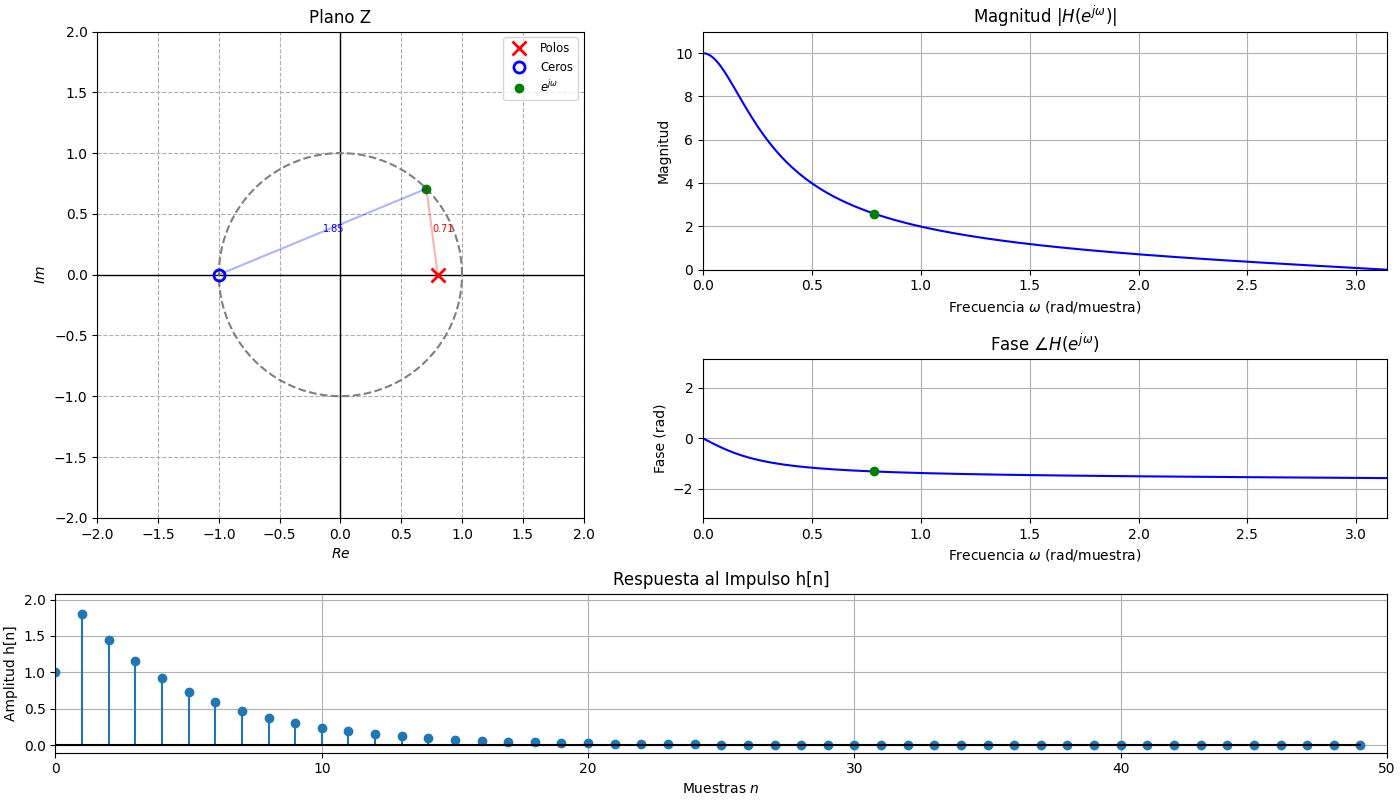

In [13]:
polos_1, ceros_1 = ['0.8'], ['-1']
motor_exp1 = crear_motor(polos_1, ceros_1)
exp_1 = InterfazPlanoZ(motor_exp1)

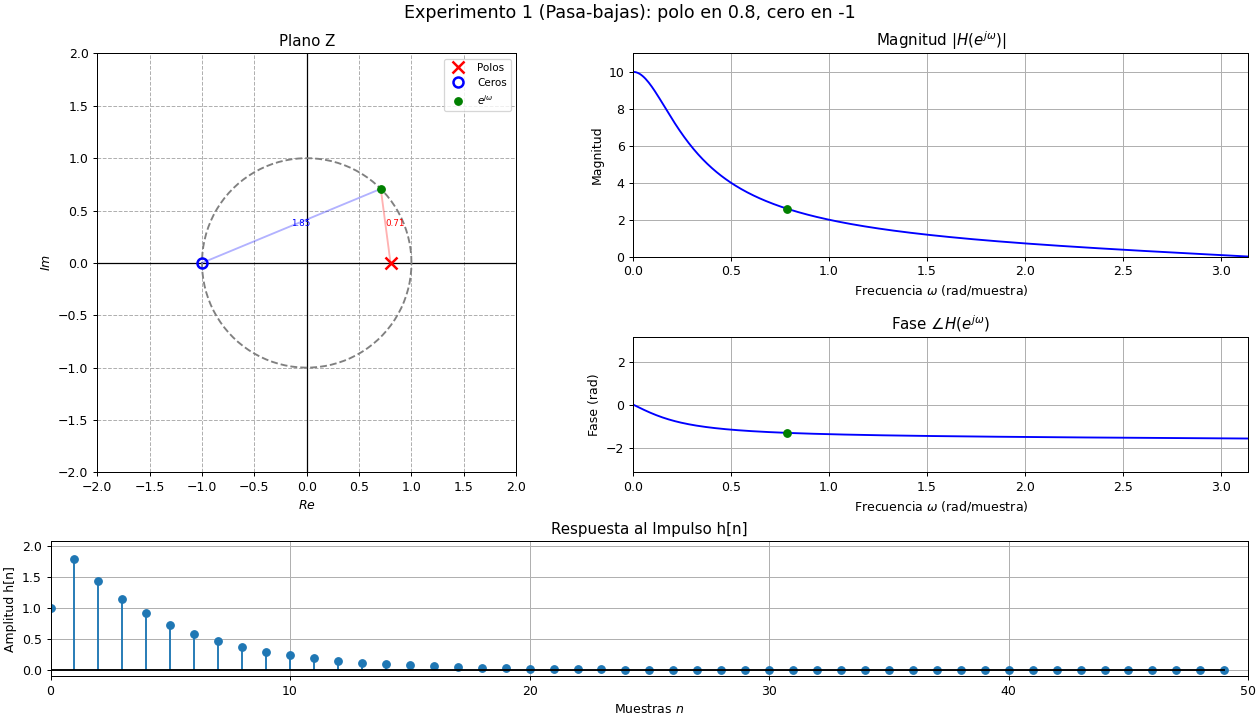

Tipo,Posición,Distancia a e^jω
Cero,-1.00+0.00j,1.8478
Polo,0.80+0.00j,0.7132


In [14]:
# Resultado estático del experimento
mostrar_resultado(crear_motor(polos_1, ceros_1), omega=np.pi/4, titulo='Experimento 1 (Pasa-bajas): polo en 0.8, cero en -1')

### Resultados del Experimento 1

<table style="width:100%; border-collapse:collapse; text-align:center;">
  <thead>
    <tr>
      <th style="width:30%; padding:8px; border:1px solid #888;">Elemento</th>
      <th style="width:70%; padding:8px; border:1px solid #888;">Valor</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Ceros</td>
      <td style="padding:8px; border:1px solid #888;">$z=-1$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Polos</td>
      <td style="padding:8px; border:1px solid #888;">$z=0.8$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Función de transferencia</td>
      <td style="padding:8px; border:1px solid #888;">$H(z)=\dfrac{z+1}{z-0.8}$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Respuesta al impulso</td>
      <td style="padding:8px; border:1px solid #888;">$h[n]=\delta[n]+1.8\,(0.8)^{n-1}\,u[n-1]$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Estabilidad</td>
      <td style="padding:8px; border:1px solid #888;">Estable, porque el polo cumple $\lvert p\rvert = 0.8 < 1$</td>
    </tr>
  </tbody>
</table>

<br>

**Magnitud:** $\lvert H(0)\rvert=10$, $\lvert H(\pi/2)\rvert\approx 1.1$, $\lvert H(\pi)\rvert=0$.
**Fase:** va de $0$ en $\omega=0$ a $-\pi/2$ cerca de $\omega=\pi$.

**Conclusión:** el cero en $z=-1$ (que corresponde a $\omega=\pi$) reduce las frecuencias altas, mientras que el polo cerca de $z=1$ aumenta las frecuencias bajas. Por esta razón, el sistema funciona como un **filtro pasa-bajas**. Cuando el polo se acerca a 1, la ganancia en DC aumenta (con un polo en 0.95 llega a 40) y el cambio entre las frecuencias que deja pasar y las que reduce es más pronunciado. En cambio, al acercar el polo al origen (0.5), la ganancia baja a 4 y el cambio es más gradual. Finalmente, la respuesta al impulso disminuye poco a poco porque el polo es real, positivo y se encuentra dentro del círculo unitario.

## Experimento 2 (Pasa-altas)

De la misma manera que en el experimento anterior, se fueron colocando polos y ceros de manera experimental, sin embargo desde un inició se probó a colocar los valores obtenidos para el filtro-pasabajas pero con el signo contrario, esto debido a que un filtro pasa-altas es reflejo de un filtro-pasabajas


De forma que si se colocan en el programa los valores:
* Polos: $-0.8$
* Ceros: $1$

$$H(z) = \frac{z -1}{z + 0.8}$$

El resultado obtenido (filtro pasa-altas) coincide con el razonamiento que se ha estado siguiente, ya que al colocar un **cero** en `1` hace que la magniud sea cero cuando al frecuencia angular sea cero ($\omega = 0$) mientras que al colocar un **polo** en `-0.8` hace que la magnitud aumente de manera significativa para frecuencais altas.

De igual forma si se coloca el **polo** más a la derecha  se obtiene un filtro con una transición más suave

Output()

Output()

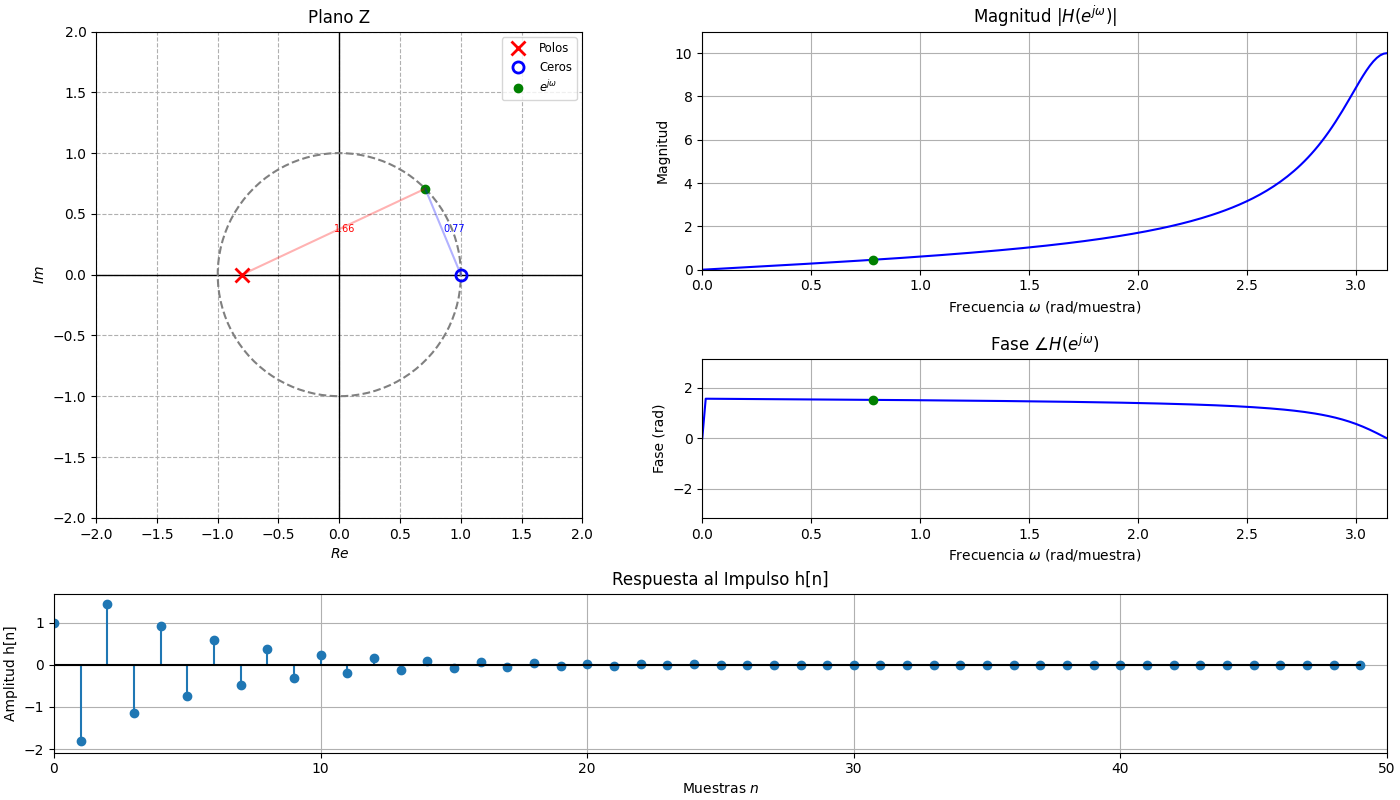

In [15]:
polos_2, ceros_2 = ['-0.8'], ['1']
motor_exp2 = crear_motor(polos_2, ceros_2)
exp_2 = InterfazPlanoZ(motor_exp2)

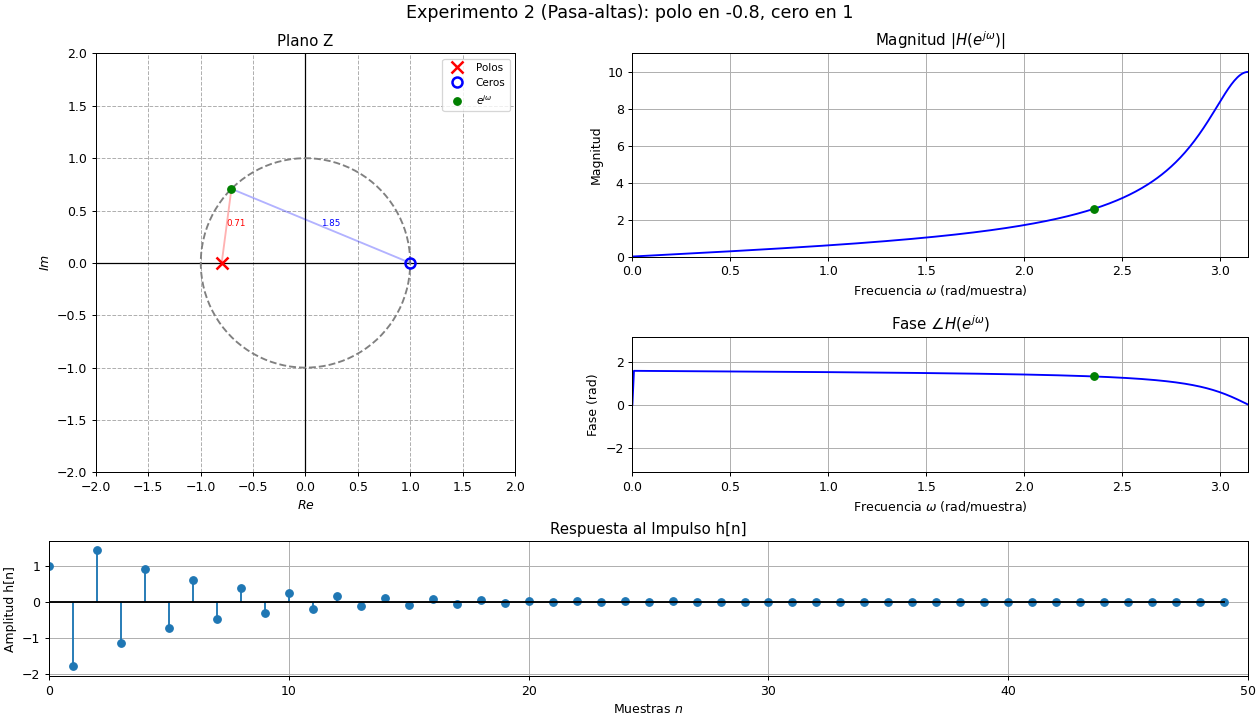

Tipo,Posición,Distancia a e^jω
Cero,1.00+0.00j,1.8478
Polo,-0.80+0.00j,0.7132


In [16]:
# Resultado estático del experimento
mostrar_resultado(crear_motor(polos_2, ceros_2), omega=3*np.pi/4, titulo='Experimento 2 (Pasa-altas): polo en -0.8, cero en 1')

### Resultados del Experimento 2

<table style="width:100%; border-collapse:collapse; text-align:center;">
  <thead>
    <tr>
      <th style="width:30%; padding:8px; border:1px solid #888;">Elemento</th>
      <th style="width:70%; padding:8px; border:1px solid #888;">Valor</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Ceros</td>
      <td style="padding:8px; border:1px solid #888;">$z=1$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Polos</td>
      <td style="padding:8px; border:1px solid #888;">$z=-0.8$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Función de transferencia</td>
      <td style="padding:8px; border:1px solid #888;">$H(z)=\dfrac{z-1}{z+0.8}$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Respuesta al impulso</td>
      <td style="padding:8px; border:1px solid #888;">$h[n]=\delta[n]-1.8\,(-0.8)^{n-1}\,u[n-1]$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Estabilidad</td>
      <td style="padding:8px; border:1px solid #888;">Estable, porque el polo cumple $\lvert p\rvert = 0.8 < 1$</td>
    </tr>
  </tbody>
</table>

<br>

**Magnitud:** $\lvert H(0)\rvert=0$, $\lvert H(\pi/2)\rvert\approx 1.1$, $\lvert H(\pi)\rvert=10$.
**Fase:** parte de $\pi/2$ en $\omega\approx0$ y tiende a $0$ en $\omega=\pi$.

**Conclusión:** este sistema es el reflejo del experimento 1 ($z\to -z$). El cero en $z=1$ elimina las frecuencias bajas, mientras que el polo en $-0.8$, cercano a $z=-1$, aumenta las frecuencias altas. Por esta razón, funciona como un **filtro pasa-altas**. Al alejar el polo de $-1$ (por ejemplo, hasta $-0.5$), la ganancia máxima baja a 4 y el cambio entre las frecuencias que deja pasar y las que reduce es más suave. En la respuesta al impulso $h[n]$, el signo cambia en cada muestra porque el polo es real negativo, mientras que su amplitud disminuye porque se encuentra dentro del círculo unitario.

## Experimento 3 (Notch)

Los filtros tipos Notch son aquellos que eliminan una sola frecuencia y dejan el resto de la señal intacta.

Probando de polos y ceros de manera experimental, se llego al Filtro tipo Notch colocando valores de la siguiente fomra

De forma que si se colocan en el programa los valores:
* Polos: $0.9j, \, -0.9j$
* Ceros: $j, \, -j$

$$H(z) = \frac{(z -1j)(z + 1j)}{(z-0.9j)(z+0.9j)}$$

El comportamiento observado a partir de estos valores es que cuando se colocan **ceros** directamente sobre el circulo unitario se garantiza que en esas frecuencias el resultado sea `0`.En este caso los valores que se pusieron en cero corresponden para $\omega = \pi / 2$. Sin embargo al colocar estos ceros se puede observar en la gráfica que la caída/supresión es muy ancha, de forma que se eliminan más de una sola frecuencia.

Por lo que al colocar **polos** detrás de los ceros (esto para garantizar estabilidad) se lográ que la caída solo sea para valores cercanos a la frecuencai que sed esea eliminar, en este caso $\omega = \pi / 2$



Output()

Output()

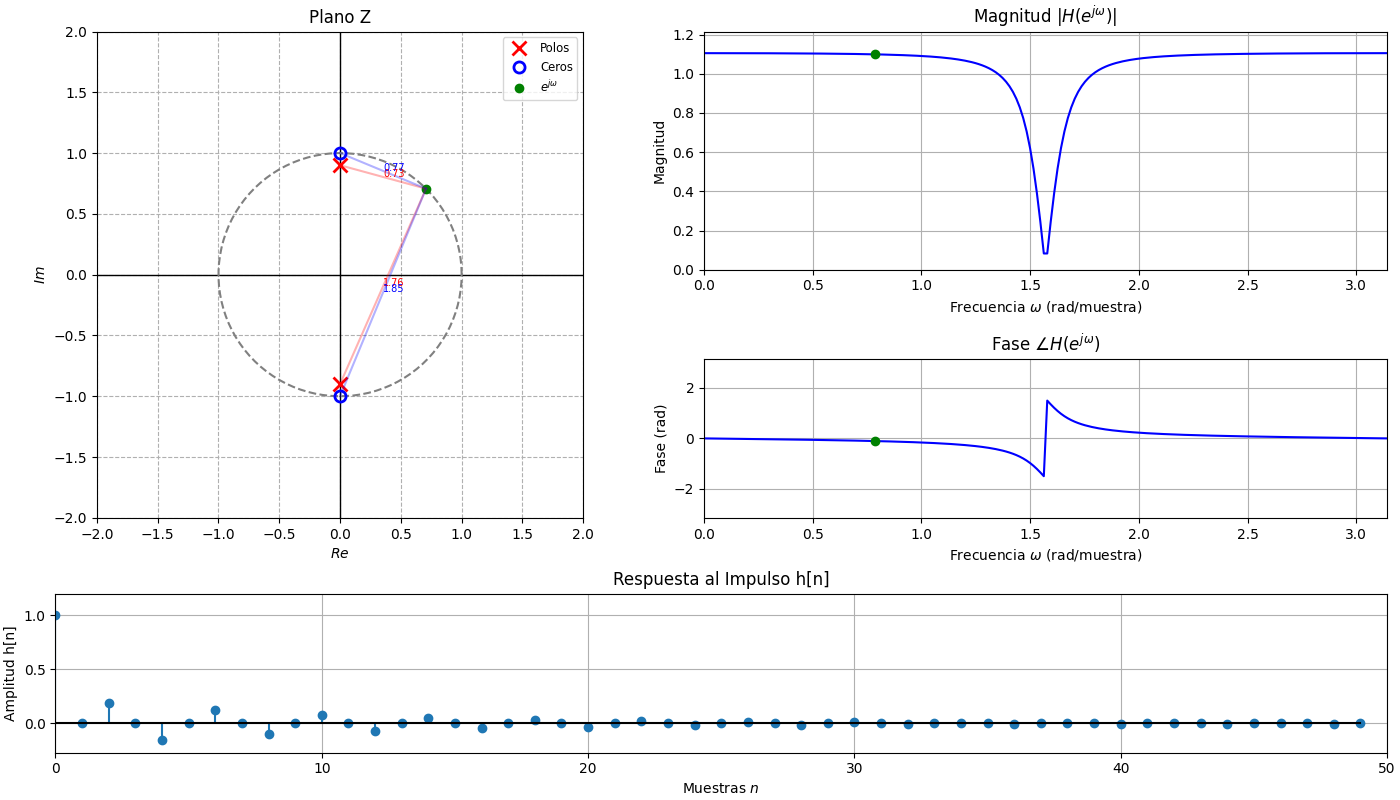

In [17]:
polos_3, ceros_3 = ['0.9j'], ['1j']
motor_exp3 = crear_motor(polos_3, ceros_3)
exp_3 = InterfazPlanoZ(motor_exp3)

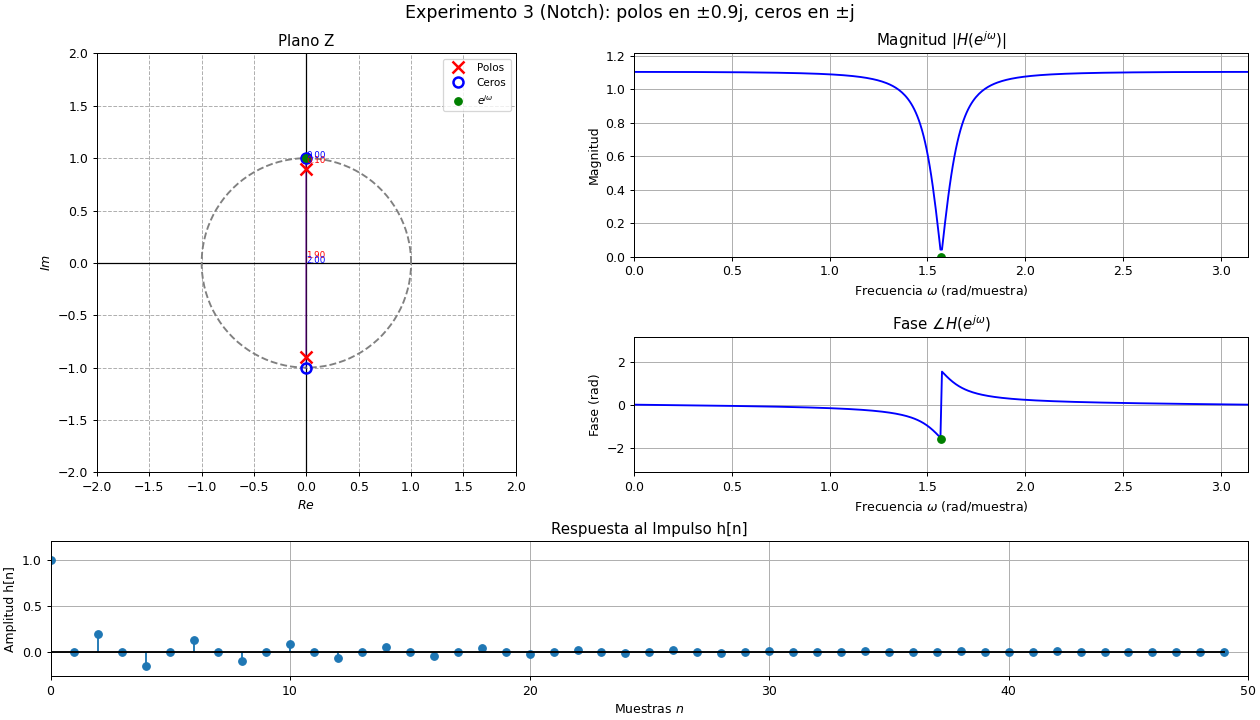

Tipo,Posición,Distancia a e^jω
Cero,0.00+1.00j,0.0000
Cero,0.00-1.00j,2.0000
Polo,0.00+0.90j,0.1000
Polo,0.00-0.90j,1.9000


In [18]:
# Resultado estático del experimento
mostrar_resultado(crear_motor(polos_3, ceros_3), omega=np.pi/2, titulo='Experimento 3 (Notch): polos en ±0.9j, ceros en ±j')

### Resultados del Experimento 3

<table style="width:100%; border-collapse:collapse; text-align:center;">
  <thead>
    <tr>
      <th style="width:30%; padding:8px; border:1px solid #888;">Elemento</th>
      <th style="width:70%; padding:8px; border:1px solid #888;">Valor</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Ceros</td>
      <td style="padding:8px; border:1px solid #888;">$z=\pm j$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Polos</td>
      <td style="padding:8px; border:1px solid #888;">$z=\pm 0.9j$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Función de transferencia</td>
      <td style="padding:8px; border:1px solid #888;">$H(z)=\dfrac{z^2+1}{z^2+0.81}$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Frecuencia rechazada</td>
      <td style="padding:8px; border:1px solid #888;">$\omega=\pi/2$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Respuesta al impulso</td>
      <td style="padding:8px; border:1px solid #888;">$h[0]=1$; muestras impares nulas; para $n\ge2$ pares, $h[n]=0.19\,(-0.81)^{(n-2)/2}$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">Estabilidad</td>
      <td style="padding:8px; border:1px solid #888;">Estable, porque los polos cumplen $\lvert p\rvert = 0.9 < 1$</td>
    </tr>
  </tbody>
</table>

<br>

**Magnitud:** $\lvert H(\pi/2)\rvert=0$ y $\lvert H\rvert\approx 1.1$ en $\omega=0$ y $\omega=\pi$. El ancho de la caída a $-3$ dB es de aproximadamente $0.17$ rad.

**Comparación sin polos:** cuando solo se utilizan ceros, la caída de la ganancia alrededor de la frecuencia eliminada es muy amplia y la ganancia en el resto del espectro es 2. Al agregar polos con el mismo ángulo que los ceros, pero dentro del círculo unitario, el rechazo se hace más estrecho y el resto de las frecuencias mantienen una ganancia casi constante. Con un radio de $0.99$, el ancho del rechazo baja a aproximadamente $0.02$ rad, mientras que con un radio de $0.5$ aumenta a aproximadamente $0.57$ rad.

**Conclusión:** los **ceros** determinan qué frecuencia se elimina (según su ángulo), mientras que los **polos** controlan qué tan estrecha es la zona de rechazo (según su cercanía al círculo unitario). De esta manera, se obtiene un **filtro notch** que elimina la frecuencia $\omega=\pi/2$.

## Experimento 4 (Resonancia)

Al modificar el radio de un par de polos conjugados se observó el siguiente comportamiendo:

Al ingresar como polos complejos conjugados se obtiene en la gráfica una campana de Gauss, donde la frecuencia donde esta el pico más alto se le conoce como frecuencia resonancia, de forma que la camapana de Gauss estara centrada en esta frecuencia de Resonancia

Al variar el radio, se puede observar que al tener un radio cercano a uno, es decir al colocar un polo como $0.95j$, la campana tiene un pico de magnitud alto y estrecho. Mientras que si se coloca un polo de radio lejano a uno como $0.5+0.5j$ el pcico de la camapana de desplaza hacia la iquierda de forma que la magnitud del pico es más baja y ancha.

Si se agrega un polo con parte real negativa como $-0.7+0.7j$ el picpo de la campana de desplaza hacia la derecha, dado que el radio del polo es cercano a 1 (0.99) el pico de la magnitud es significativamente mayor además que en la respuesta al impuslo se puede observar como no pierde amplitud.

Al ingresar un polo que su radio sea mayor a 1 como $0.8+0.8j$ (radio = 1.13) hace que los polo se encuentran fuera del circulo unitario, de forma que el sistema es inestable, esto se puede confirmar al observar la gráfica al impulso unitario, donde h[n] crece de manera exponencial a medida que aumentan las muestras.

Output()

Output()

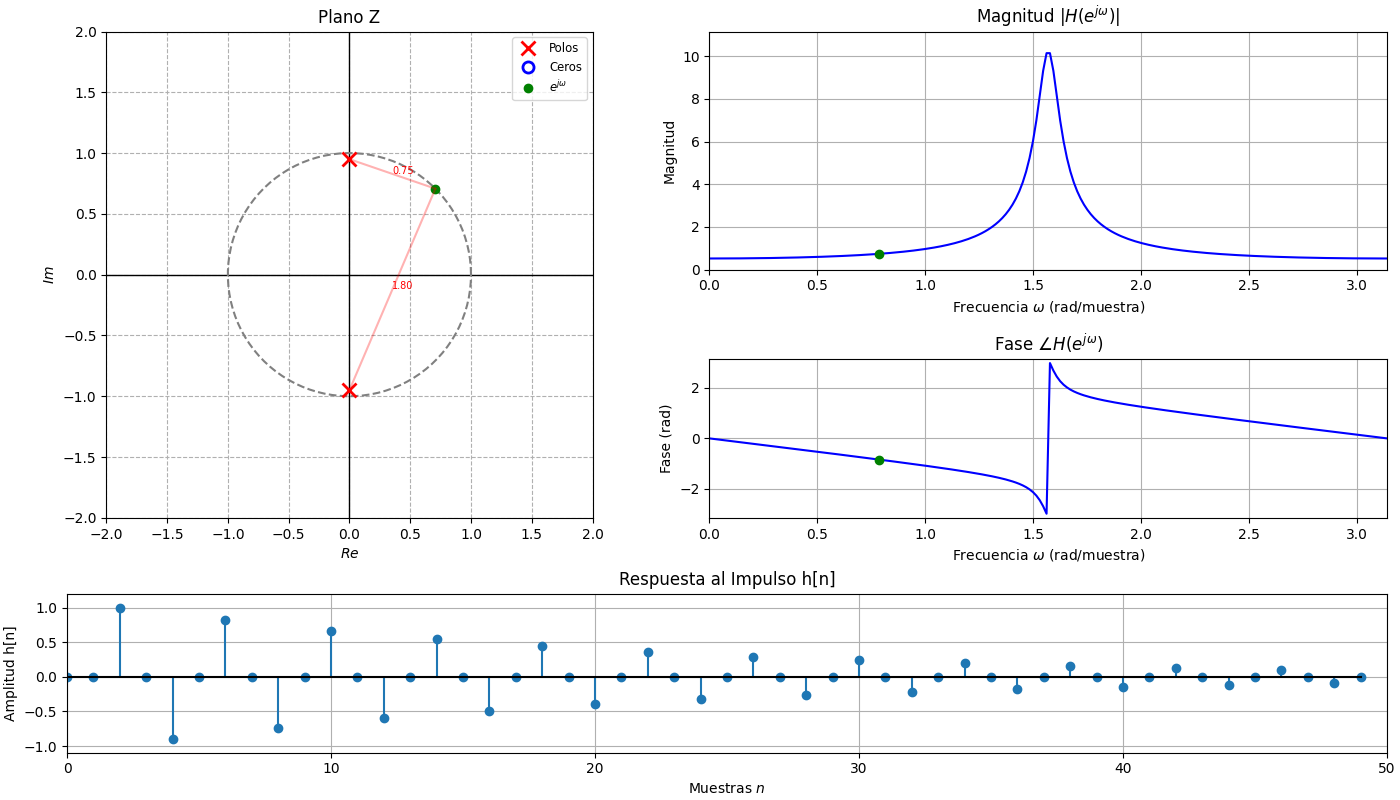

In [19]:
polos_4_1, ceros_4_1 = ['0.95j'], []
motor_exp4_1 = crear_motor(polos_4_1, ceros_4_1)
exp_4_1 = InterfazPlanoZ(motor_exp4_1)

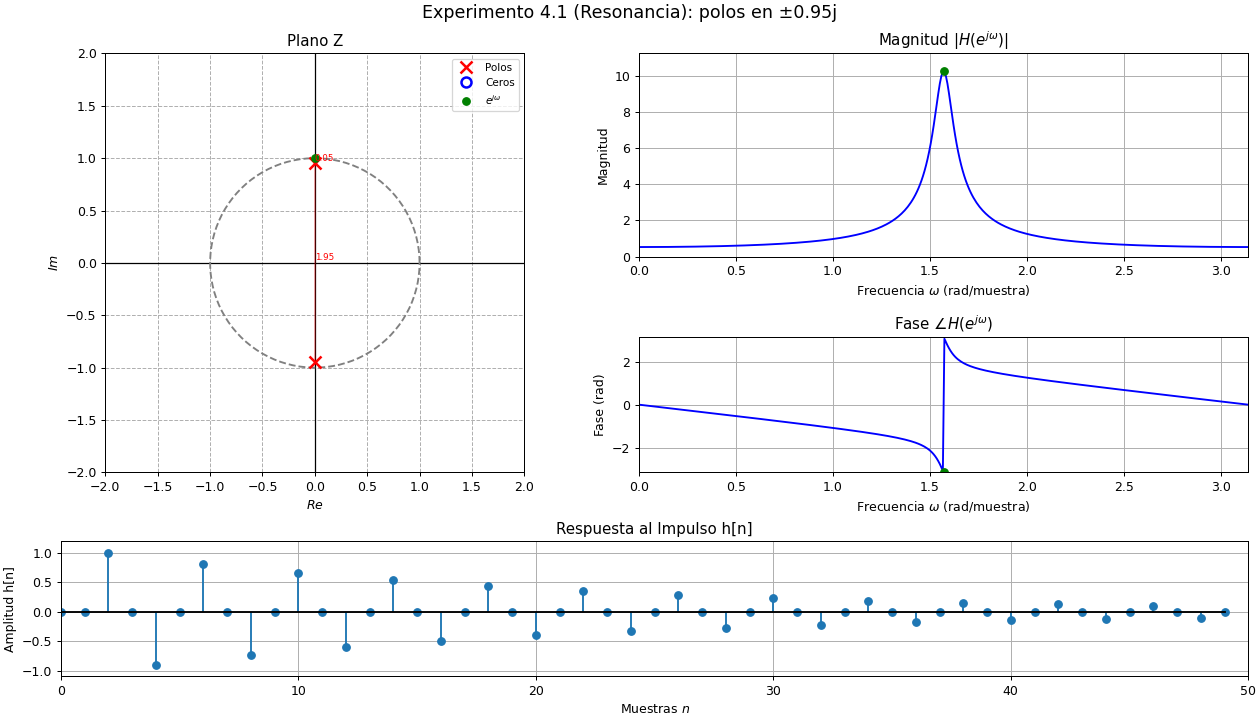

Tipo,Posición,Distancia a e^jω
Polo,0.00+0.95j,0.0500
Polo,0.00-0.95j,1.9500


In [20]:
# Resultado estático del experimento
mostrar_resultado(crear_motor(polos_4_1, ceros_4_1), omega=np.pi/2, titulo='Experimento 4.1 (Resonancia): polos en ±0.95j')

Output()

Output()

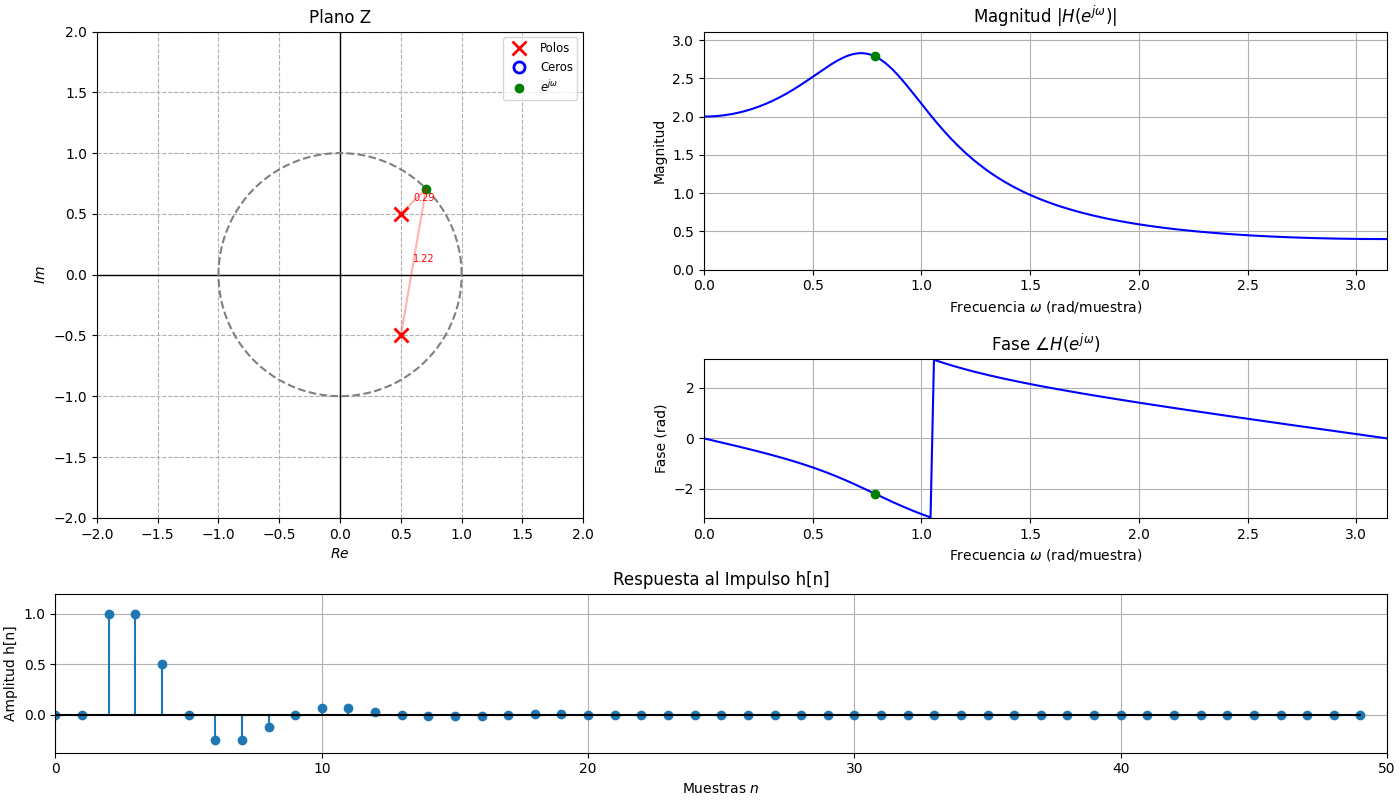

In [21]:
polos_4_2, ceros_4_2 = ['0.5+0.5j'], []
motor_exp4_2 = crear_motor(polos_4_2, ceros_4_2)
exp_4_2 = InterfazPlanoZ(motor_exp4_2)

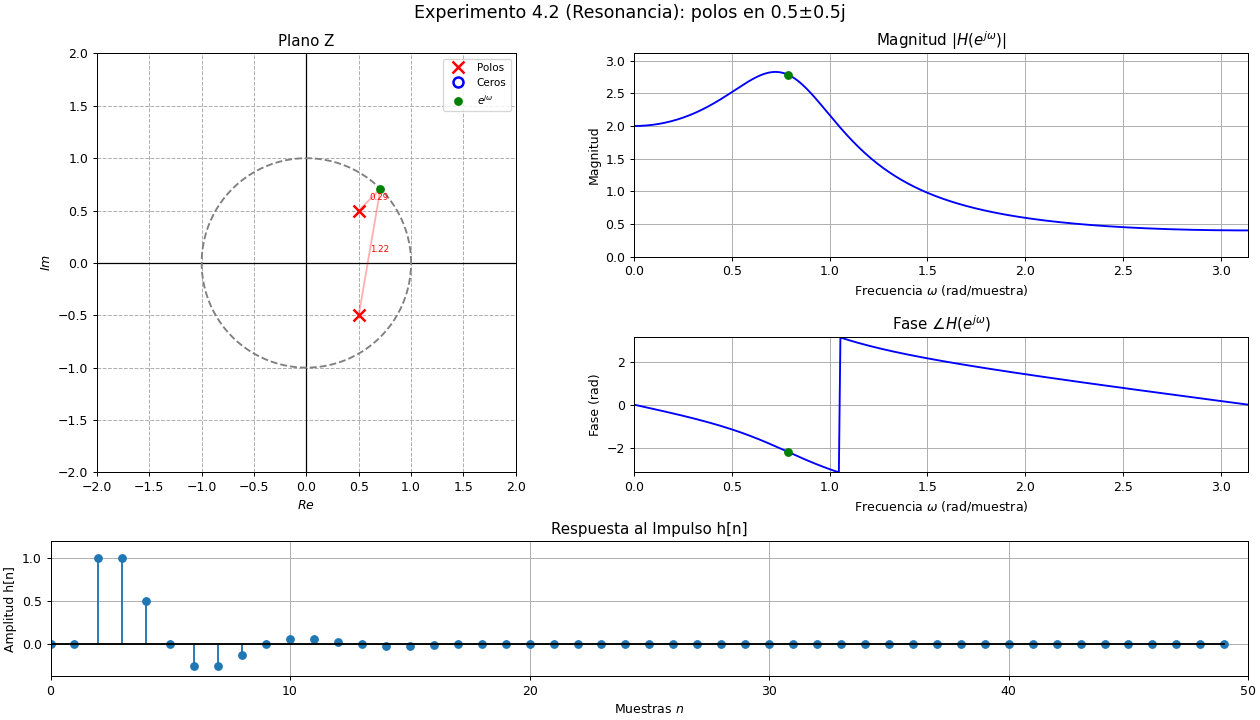

Tipo,Posición,Distancia a e^jω
Polo,0.50+0.50j,0.2929
Polo,0.50-0.50j,1.2247


In [22]:
# Resultado estático del experimento
mostrar_resultado(crear_motor(polos_4_2, ceros_4_2), omega=np.pi/4, titulo='Experimento 4.2 (Resonancia): polos en 0.5±0.5j')

Output()

Output()

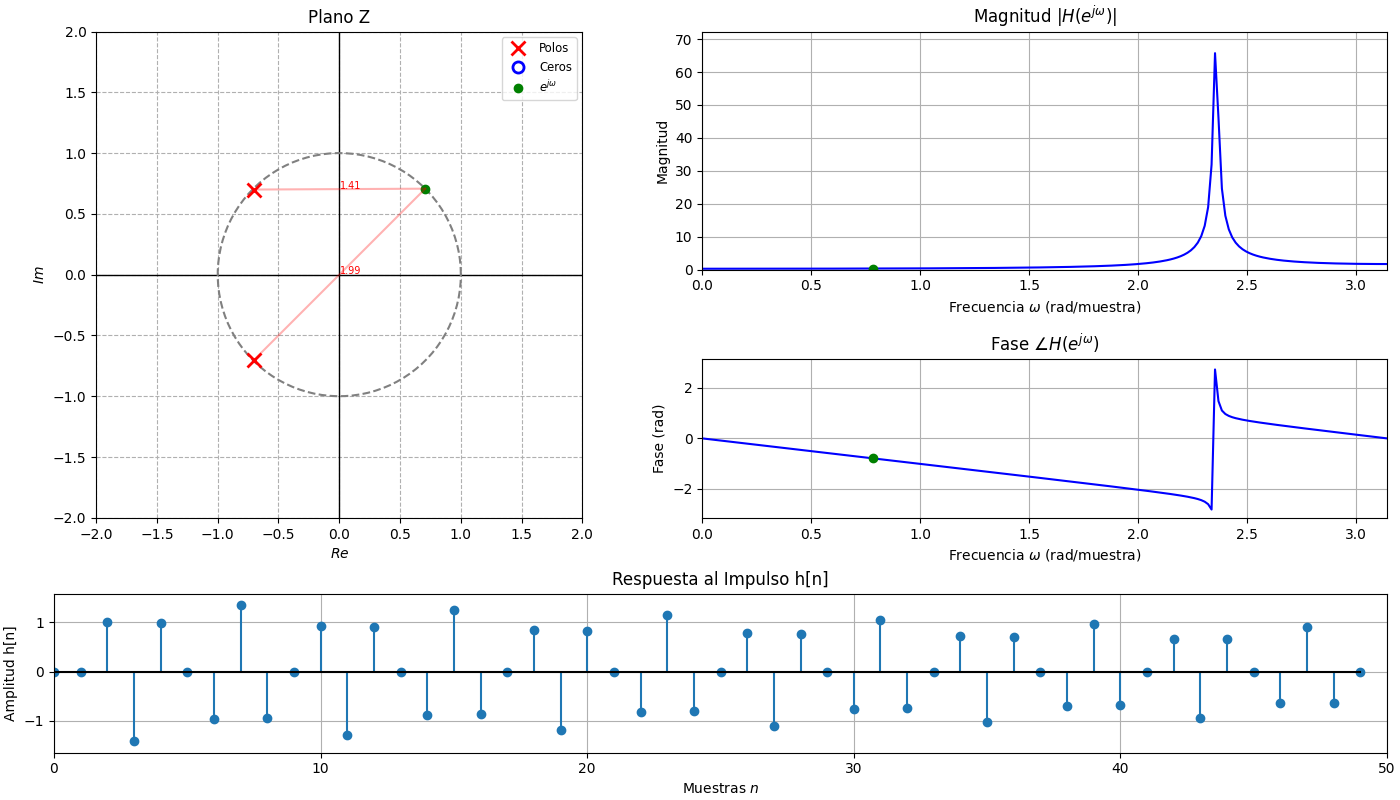

In [23]:
polos_4_3, ceros_4_3 = ['-0.7+0.7j'], []
motor_exp4_3 = crear_motor(polos_4_3, ceros_4_3)
exp_4_3 = InterfazPlanoZ(motor_exp4_3)

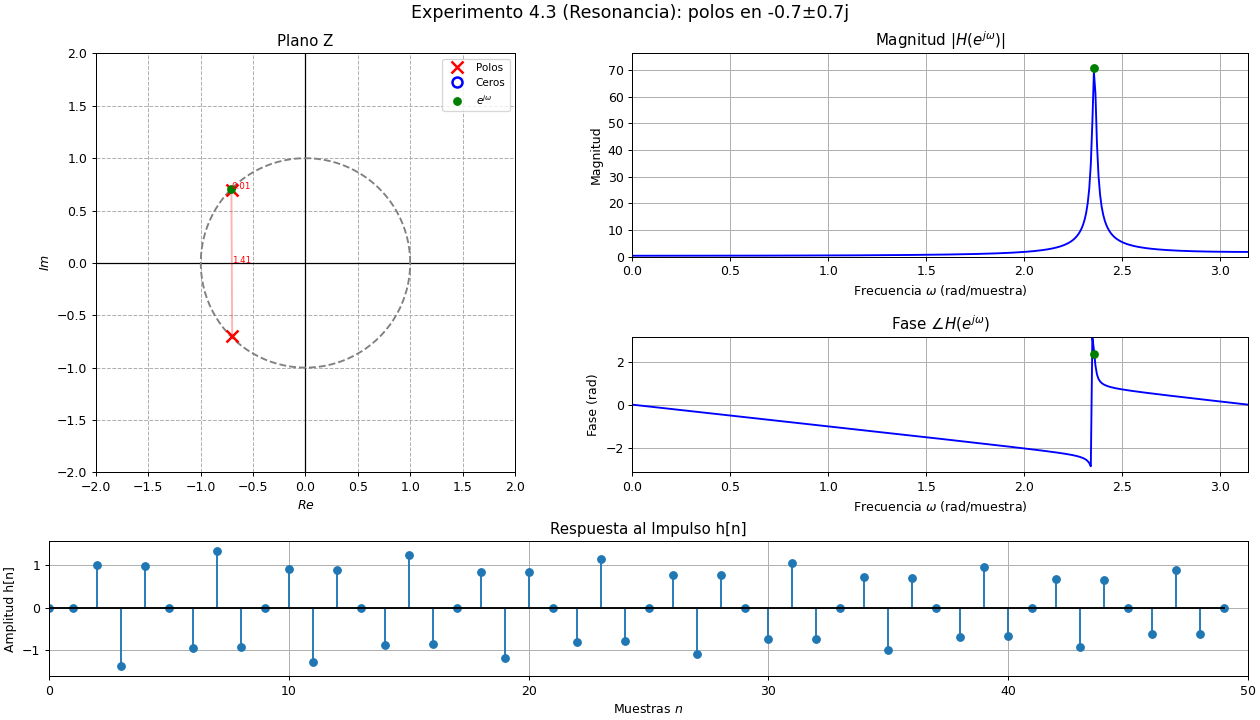

Tipo,Posición,Distancia a e^jω
Polo,-0.70+0.70j,0.0101
Polo,-0.70-0.70j,1.4071


In [24]:
# Resultado estático del experimento
mostrar_resultado(crear_motor(polos_4_3, ceros_4_3), omega=3*np.pi/4, titulo='Experimento 4.3 (Resonancia): polos en -0.7±0.7j')

Output()

Output()

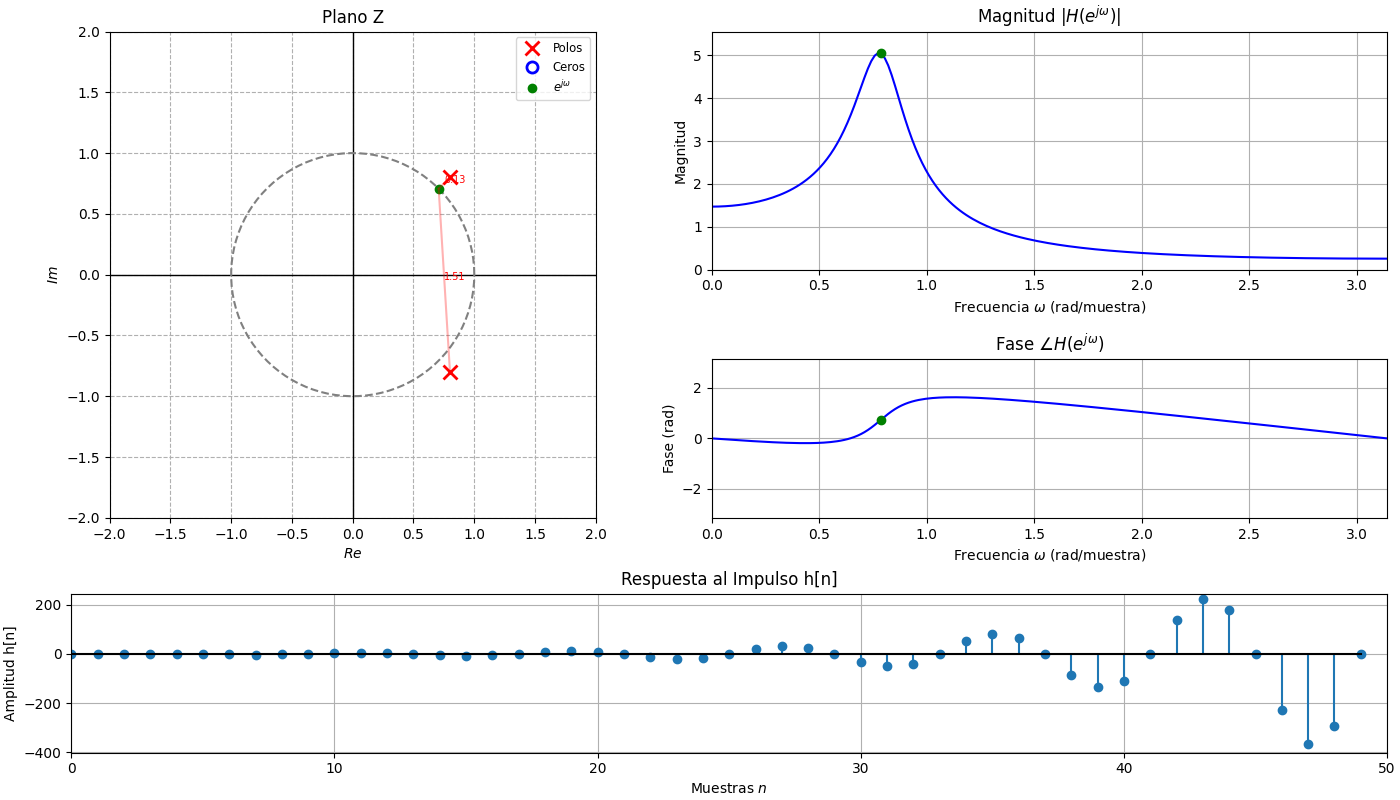

In [25]:
polos_4_4, ceros_4_4 = ['0.8+0.8j'], []
motor_exp4_4 = crear_motor(polos_4_4, ceros_4_4)
exp_4_4 = InterfazPlanoZ(motor_exp4_4)

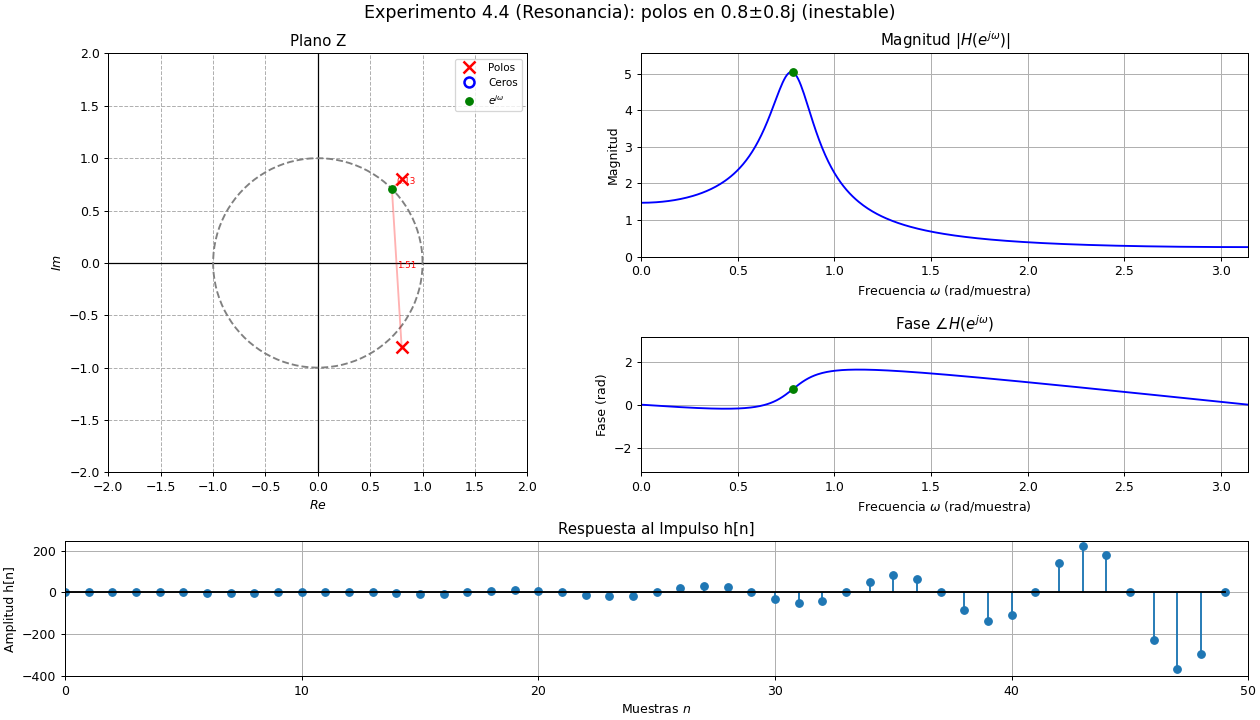

Tipo,Posición,Distancia a e^jω
Polo,0.80+0.80j,0.1314
Polo,0.80-0.80j,1.5100


In [26]:
# Resultado estático del experimento
mostrar_resultado(crear_motor(polos_4_4, ceros_4_4), omega=np.pi/4, titulo='Experimento 4.4 (Resonancia): polos en 0.8±0.8j (inestable)')

### Resultados del Experimento 4

<table style="width:100%; border-collapse:collapse; text-align:center;">
  <thead>
    <tr>
      <th style="padding:8px; border:1px solid #888;">Caso</th>
      <th style="padding:8px; border:1px solid #888;">Polos</th>
      <th style="padding:8px; border:1px solid #888;">$H(z)$ factorizada y expandida</th>
      <th style="padding:8px; border:1px solid #888;">Radio</th>
      <th style="padding:8px; border:1px solid #888;">Ángulo</th>
      <th style="padding:8px; border:1px solid #888;">Pico en $\omega$</th>
      <th style="padding:8px; border:1px solid #888;">Pico $\lvert H\rvert$</th>
      <th style="padding:8px; border:1px solid #888;">Estabilidad</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding:8px; border:1px solid #888;">4.1</td>
      <td style="padding:8px; border:1px solid #888;">$\pm0.95j$</td>
      <td style="padding:8px; border:1px solid #888;">$\dfrac{1}{(z-0.95j)(z+0.95j)}$<br>$=\dfrac{1}{z^2+0.9025}$</td>
      <td style="padding:8px; border:1px solid #888;">0.95</td>
      <td style="padding:8px; border:1px solid #888;">$\pi/2$</td>
      <td style="padding:8px; border:1px solid #888;">$\pi/2$</td>
      <td style="padding:8px; border:1px solid #888;">$\approx 10.3$</td>
      <td style="padding:8px; border:1px solid #888;">Estable</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">4.2</td>
      <td style="padding:8px; border:1px solid #888;">$0.5\pm0.5j$</td>
      <td style="padding:8px; border:1px solid #888;">$\dfrac{1}{(z-0.5-0.5j)(z-0.5+0.5j)}$<br>$=\dfrac{1}{z^2-z+0.5}$</td>
      <td style="padding:8px; border:1px solid #888;">0.71</td>
      <td style="padding:8px; border:1px solid #888;">$\pi/4$</td>
      <td style="padding:8px; border:1px solid #888;">$\approx 0.72$</td>
      <td style="padding:8px; border:1px solid #888;">$\approx 2.8$</td>
      <td style="padding:8px; border:1px solid #888;">Estable; $h[n]$ se extingue rápido</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">4.3</td>
      <td style="padding:8px; border:1px solid #888;">$-0.7\pm0.7j$</td>
      <td style="padding:8px; border:1px solid #888;">$\dfrac{1}{(z+0.7-0.7j)(z+0.7+0.7j)}$<br>$=\dfrac{1}{z^2+1.4z+0.98}$</td>
      <td style="padding:8px; border:1px solid #888;">0.99</td>
      <td style="padding:8px; border:1px solid #888;">$3\pi/4$</td>
      <td style="padding:8px; border:1px solid #888;">$\approx 2.36$</td>
      <td style="padding:8px; border:1px solid #888;">$\approx 70.7$</td>
      <td style="padding:8px; border:1px solid #888;">Casi marginal; $h[49]\approx 0.86$</td>
    </tr>
    <tr>
      <td style="padding:8px; border:1px solid #888;">4.4</td>
      <td style="padding:8px; border:1px solid #888;">$0.8\pm0.8j$</td>
      <td style="padding:8px; border:1px solid #888;">$\dfrac{1}{(z-0.8-0.8j)(z-0.8+0.8j)}$<br>$=\dfrac{1}{z^2-1.6z+1.28}$</td>
      <td style="padding:8px; border:1px solid #888;">1.13</td>
      <td style="padding:8px; border:1px solid #888;">$\pi/4$</td>
      <td style="padding:8px; border:1px solid #888;">no válida</td>
      <td style="padding:8px; border:1px solid #888;">no válida</td>
      <td style="padding:8px; border:1px solid #888;"><b>Inestable</b>; $h[49]\approx 600$</td>
    </tr>
  </tbody>
</table>

<br>



**Conclusión:** el **ángulo** del polo determina la frecuencia de resonancia, mientras que el **radio** controla qué tan pronunciado es el pico. Cuando el radio está cerca de 1, el pico es alto y estrecho, y la respuesta al impulso $h[n]$ tarda más en disminuir. En cambio, cuando el radio es pequeño, el pico es más bajo y ancho, y $h[n]$ disminuye más rápido. Cuando el radio supera 1 (caso 4.4), el sistema se vuelve **inestable**, ya que $h[n]$ crece exponencialmente. Por esta razón, la curva de magnitud deja de representar una respuesta en frecuencia válida, porque la transformada de Fourier de $h[n]$ no converge.

## Explicación: efecto de la posición de polos y ceros

La respuesta en frecuencia se obtiene evaluando $H(z)$ sobre el círculo unitario, es decir, cuando $z=e^{j\omega}$:

$$|H(e^{j\omega})| = |K|\,\frac{\prod |e^{j\omega}-z_k|}{\prod |e^{j\omega}-p_k|}, \qquad \angle H(e^{j\omega}) = \sum \angle(e^{j\omega}-z_k) - \sum \angle(e^{j\omega}-p_k)$$

La magnitud se calcula multiplicando las distancias de $e^{j\omega}$ a los ceros y dividiendo el resultado entre las distancias a los polos. Esto es lo que representan las líneas azules y rojas de la interfaz.

**\*\*Ceros.\*\*** Reducen la magnitud de ciertas frecuencias. Si un cero está sobre el círculo unitario, elimina por completo la frecuencia que corresponde a su ángulo. Si está cerca, produce una caída importante. Por lo tanto, su ángulo indica qué frecuencia se atenúa.

**\*\*Polos.\*\*** Aumentan la magnitud. Cuando un polo está cerca del círculo unitario, produce un pico en la frecuencia que corresponde a su ángulo. Cuanto más cerca esté de $|z|=1$, más alto y estrecho será el pico. Al acercarlo al origen, el pico disminuye y se vuelve más ancho.

**\*\*Ubicación en el círculo.\*\*** Los puntos cercanos a $z=1$ ($\omega=0$) afectan principalmente las bajas frecuencias, mientras que los cercanos a $z=-1$ ($\omega=\pi$) afectan las altas frecuencias. Un par de polos o ceros conjugados actúa sobre la frecuencia indicada por su ángulo $\omega_0$.

**\*\*Fase.\*\*** Cada polo y cero también modifica la fase de la señal. Este cambio es más pronunciado cuando se encuentran cerca del círculo unitario.

**\*\*Estabilidad.\*\*** Un sistema LTI causal es estable si y solo si **\*\*todos sus polos están dentro del círculo unitario\*\*** ($|p|<1$). En ese caso, la respuesta al impulso $h[n]$ disminuye con el tiempo, de acuerdo con $|p|^n$. Si $|p|=1$, la respuesta no disminuye y, en general, el sistema no es estable. Si $|p|>1$, la respuesta crece exponencialmente. Los **\*\*ceros no afectan la estabilidad\*\***. Además, cuanto más cerca esté un polo del círculo unitario, más tarda en disminuir $h[n]$.

## Conclusiones de los experimentos

1\. Los ceros reducen ciertas frecuencias y los polos aumentan su magnitud. El ángulo indica qué frecuencia se modifica y la distancia al círculo unitario determina qué tan fuerte es el efecto.

2\. **\*\*Pasa-bajas:\*\*** se obtiene con un cero en $z=-1$ y un polo cerca de $z=1$.

3\. **\*\*Pasa-altas:\*\*** se obtiene con un cero en $z=1$ y un polo cerca de $z=-1$.

4\. **\*\*Notch:\*\*** utiliza ceros sobre el círculo unitario en la frecuencia que se quiere eliminar y polos en el mismo ángulo, pero con un radio menor que 1, para hacer más estrecha la zona de rechazo.

5\. **\*\*Resonador:\*\*** utiliza polos complejos conjugados con un radio cercano a 1 para producir un pico de resonancia.

6\. Acercar los polos al círculo unitario permite concentrar el efecto en frecuencias más específicas, pero también aumenta el riesgo de que el sistema se vuelva inestable. Por eso, es necesario encontrar un equilibrio entre la selectividad y la estabilidad.

7\. Una herramienta interactiva en el plano Z permite cambiar la posición de polos y ceros y observar cómo afectan la magnitud, la fase y la respuesta al impulso $h[n]$.